# Листок № 2 — Комплексные числа

**Импорты.** `cmath` / `sympy` — комплексная арифметика; `matplotlib` — комплексная плоскость и множества Жюлиа.

In [1]:
import cmath
import numpy as np
import matplotlib.pyplot as plt
from sympy import *
init_printing()

def complex_forms(z, name='z'):
    """Алгебраическая, тригонометрическая и показательная формы."""
    r, phi = abs(z), cmath.phase(z)
    print(f'{name} = {z.real:.6g} + {z.imag:.6g}i')
    print(f'  |{name}| = {r:.6g},  arg {name} = {phi:.6g} rad ({np.degrees(phi):.4g}°)')
    print(f'  trig: {r:.6g}(cos {phi:.6g} + i sin {phi:.6g})')
    print(f'  exp:  {r:.6g} * exp(i * {phi:.6g})')
    return r, phi


---
## 2.1. Три формы комплексного выражения

### a) $\dfrac{(5+i)(7-6i)}{3+i}$


In [2]:
z_a = (5+1j)*(7-6j)/(3+1j)
complex_forms(z_a, 'a')
I = S.ImaginaryUnit
expand(((5+I)*(7-6*I))/(3+I))


a = 10 + -11i
  |a| = 14.8661,  arg a = -0.832981 rad (-47.73°)
  trig: 14.8661(cos -0.832981 + i sin -0.832981)
  exp:  14.8661 * exp(i * -0.832981)


### b) $\dfrac{(1+i)^5}{(1-i)^3}$


In [3]:
z_b = (1+1j)**5/(1-1j)**3
complex_forms(z_b, 'b')


b = 2 + -0i
  |b| = 2,  arg b = -0 rad (-0°)
  trig: 2(cos -0 + i sin -0)
  exp:  2 * exp(i * -0)


### c) $\dfrac{(-1+i\sqrt3)^{15}}{(1-i)^{20}}+\dfrac{(-1-i\sqrt3)^{15}}{(1+i)^{20}}$


In [4]:
sqrt3 = 3**0.5
z_c = (-1+1j*sqrt3)**15/(1-1j)**20 + (-1-1j*sqrt3)**15/(1+1j)**20
complex_forms(z_c, 'c')
I = S.ImaginaryUnit
expand(((-1+I*sqrt(3))**15/(1-I)**20 + (-1-I*sqrt(3))**15/(1+I)**20))


c = -64 + 0i
  |c| = 64,  arg c = 3.14159 rad (180°)
  trig: 64(cos 3.14159 + i sin 3.14159)
  exp:  64 * exp(i * 3.14159)


---
## 2.2. Уравнение $z^8 = 1+i$

Корни: $|z_k| = |1+i|^{1/8}$, $\arg z_k = \dfrac{\arg(1+i) + 2\pi k}{8}$, $k=0,\ldots,7$.


0 (1.039245318735967+0.10235672987466886j)
1 (0.6624802744001193+0.8072345499890353j)
2 (-0.1023567298746689+1.039245318735967j)
3 (-0.8072345499890353+0.6624802744001193j)
4 (-1.039245318735967-0.10235672987466883j)
5 (-0.6624802744001196-0.8072345499890349j)
6 (0.10235672987466832-1.039245318735967j)
7 (0.8072345499890349-0.6624802744001197j)


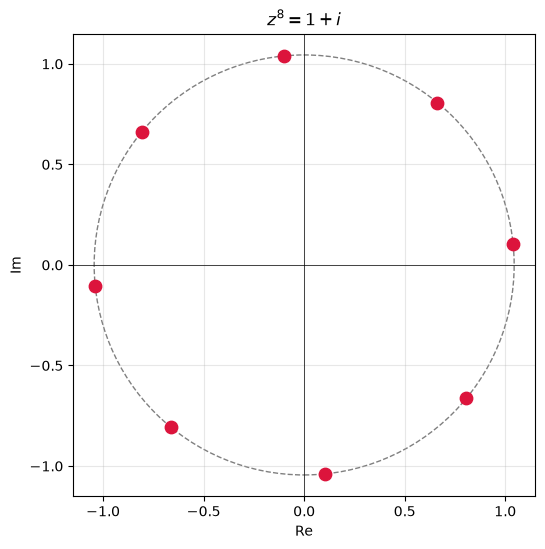

In [5]:
w = 1+1j
R, alpha = abs(w), cmath.phase(w)
roots_22 = [R**(1/8)*cmath.exp(1j*(alpha + 2*cmath.pi*k)/8) for k in range(8)]
for k, z in enumerate(roots_22):
    print(k, z)

fig, ax = plt.subplots(figsize=(6, 6))
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
ax.scatter([z.real for z in roots_22], [z.imag for z in roots_22], c='crimson', s=80, zorder=3)
ax.add_patch(plt.Circle((0, 0), R**(1/8), fill=False, ls='--', color='gray'))
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_xlabel('Re')
ax.set_ylabel('Im')
ax.set_title('$z^8 = 1+i$')
plt.show()


---
## 2.3. Корни в $\mathbb C$ и комплексная плоскость


### a) $\sqrt[8]{\,i\,}$ (главное значение)


sqrt[8](i) = 0.980785 + 0.19509i
  |sqrt[8](i)| = 1,  arg sqrt[8](i) = 0.19635 rad (11.25°)
  trig: 1(cos 0.19635 + i sin 0.19635)
  exp:  1 * exp(i * 0.19635)


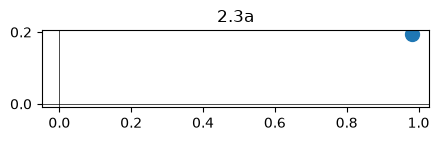

In [6]:
z_23a = cmath.exp(1j*cmath.pi/16)
complex_forms(z_23a, 'sqrt[8](i)')
plt.figure(figsize=(5, 5))
plt.scatter([z_23a.real], [z_23a.imag], s=100)
plt.axhline(0, color='k', lw=0.5)
plt.axvline(0, color='k', lw=0.5)
plt.gca().set_aspect('equal')
plt.title('2.3a')
plt.show()


### b) $\dfrac{18}{4} - \dfrac{1}{1+i\sqrt3}$


b = 4.25 + 0.433013i
  |b| = 4.272,  arg b = 0.101535 rad (5.818°)
  trig: 4.272(cos 0.101535 + i sin 0.101535)
  exp:  4.272 * exp(i * 0.101535)


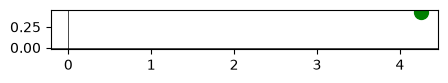

In [7]:
z_23b = 18/4 - 1/(1+1j*sqrt3)
complex_forms(z_23b, 'b')
plt.figure(figsize=(5, 5))
plt.scatter([z_23b.real], [z_23b.imag], s=100, c='green')
plt.axhline(0, color='k', lw=0.5)
plt.axvline(0, color='k', lw=0.5)
plt.gca().set_aspect('equal')
plt.show()


### c) $\sqrt[3]{\dfrac{1-5i}{1+2i} - \dfrac{5}{2-i} + 11}$


In [8]:
inner = (1-5j)/(1+2j) - 5/(2-1j) + 11
print('Подкоренное:', inner)
z_23c = inner**(1/3)
complex_forms(z_23c, 'c')
I = S.ImaginaryUnit
expand((1-5*I)/(1+2*I) - 5/(2-I) + 11)


Подкоренное: (7.2-2.4j)
c = 1.95389 + -0.210363i
  |c| = 1.96519,  arg c = -0.10725 rad (-6.145°)
  trig: 1.96519(cos -0.10725 + i sin -0.10725)
  exp:  1.96519 * exp(i * -0.10725)


### d) $\sqrt[9]{\,1-i\,}$ — все 9 корней


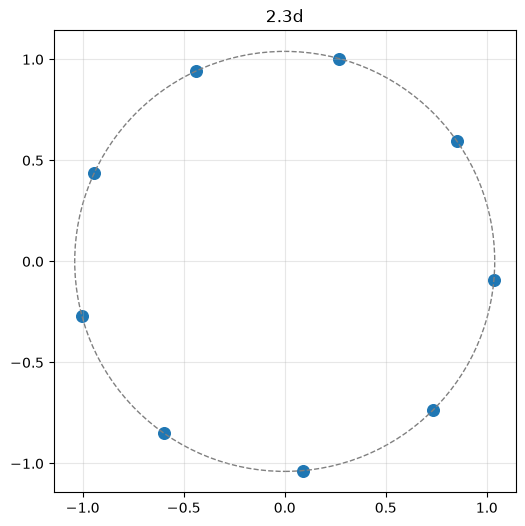

In [9]:
base = 1-1j
R, a = abs(base), cmath.phase(base)
roots_23d = [R**(1/9)*cmath.exp(1j*(a+2*cmath.pi*k)/9) for k in range(9)]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter([z.real for z in roots_23d], [z.imag for z in roots_23d], s=70)
ax.add_patch(plt.Circle((0, 0), R**(1/9), fill=False, ls='--', color='gray'))
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title('2.3d')
plt.show()


---
## 2.4. Множества на комплексной плоскости


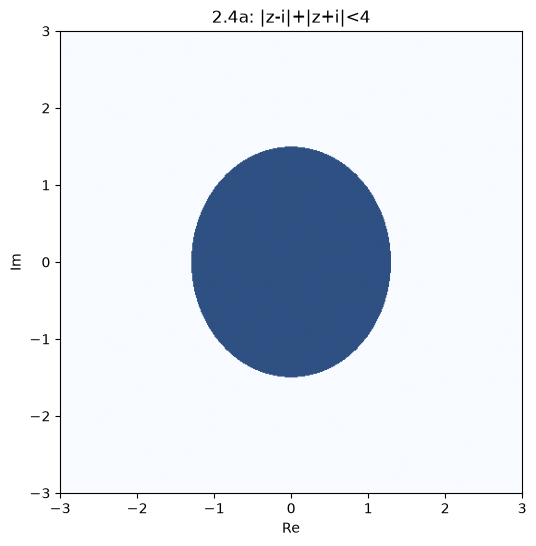

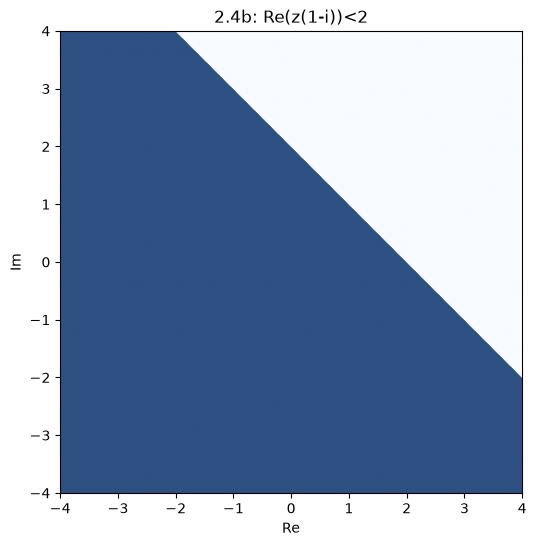

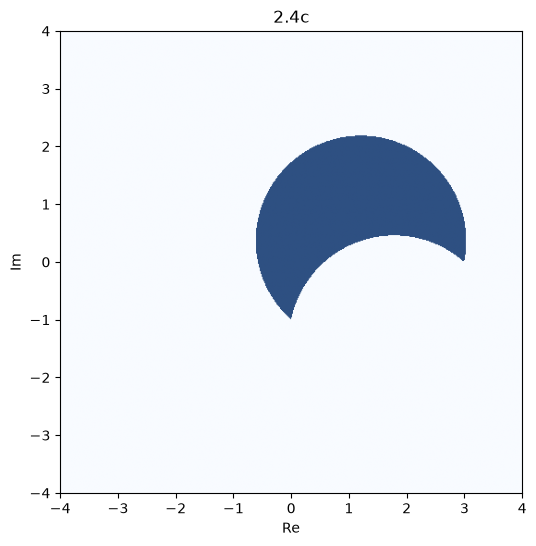

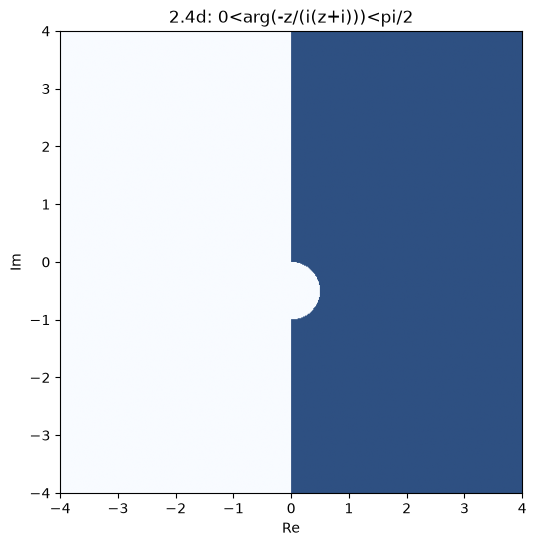

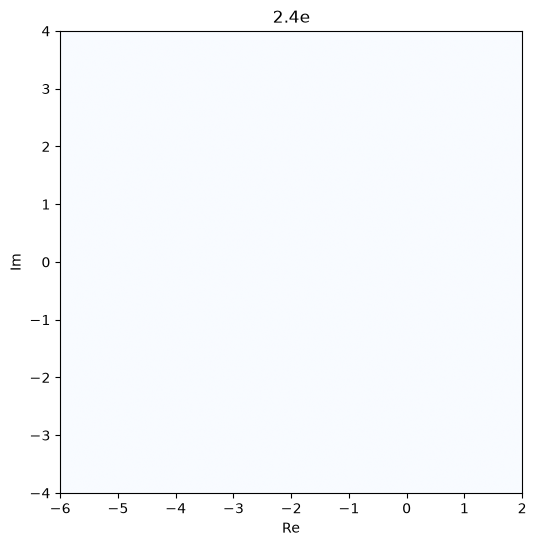

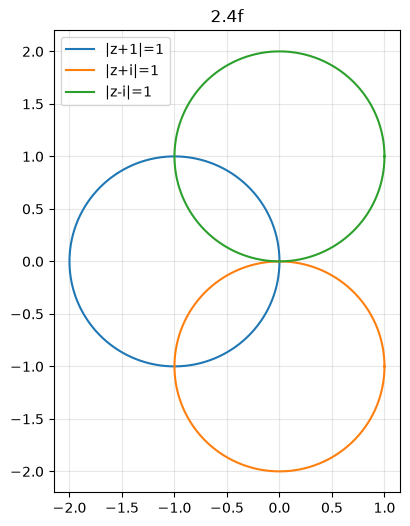

In [10]:
def plot_region(mask, title, xlim=(-4, 4), ylim=(-4, 4)):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(
        mask.astype(float),
        extent=[*xlim, *ylim],
        origin='lower',
        cmap='Blues',
        alpha=0.85,
        aspect='equal',
    )
    ax.set_xlabel('Re')
    ax.set_ylabel('Im')
    ax.set_title(title)
    plt.show()

def in_arg_band(ratio, lo, hi):
    a = np.angle(ratio)
    return (a >= lo) & (a <= hi)

n = 500
xs = np.linspace(-4, 4, n)
ys = np.linspace(-4, 4, n)
X, Y = np.meshgrid(xs, ys)
Z = X + 1j*Y

plot_region(np.abs(Z-1j) + np.abs(Z+1j) < 4, '2.4a: |z-i|+|z+i|<4', (-3, 3), (-3, 3))
plot_region((Z*(1-1j)).real < 2, '2.4b: Re(z(1-i))<2')
plot_region(in_arg_band((3-Z)/(Z+1j), -2*np.pi/3, -np.pi/3), '2.4c')
ratio_d = -Z / (1j*(Z+1j))
ad = np.angle(ratio_d)
plot_region((ad > 0) & (ad < np.pi/2), '2.4d: 0<arg(-z/(i(z+i)))<pi/2')
factor = cmath.exp(-2j*np.pi/3)
ratio_e = factor * (np.sqrt(2) - 1j*Z) / (Z + 3)
plot_region(in_arg_band(ratio_e, -2*np.pi/3, -5*np.pi/6), '2.4e', (-6, 2), (-4, 4))

fig, ax = plt.subplots(figsize=(6, 6))
t = np.linspace(0, 2*np.pi, 400)
for c, lbl in [(-1+0j, '|z+1|=1'), (-1j, '|z+i|=1'), (1j, '|z-i|=1')]:
    curve = c + np.exp(1j*t)
    ax.plot(curve.real, curve.imag, label=lbl)
ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title('2.4f')
plt.show()


---
## 2.5*. Уравнение $A|z|^2 + Bz + \overline{Bz} + C = 0$

При $A>0$ и $AC<|B|^2$ делим на $A$ и выделяем полный квадрат:
$$|z + B/A|^2 = \frac{|B|^2 - AC}{A^2}.$$
**Центр** $z_0=-B/A$, **радиус** $R=\sqrt{|B|^2-AC}/A$.


---
## 2.6. Корни $p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2$


1) |z1|+...+|z11| = 11.97338446971212
2) max Re = 1.0806017373578454 , root ≈ (1.0806017373578454-0.3238931188400023j)


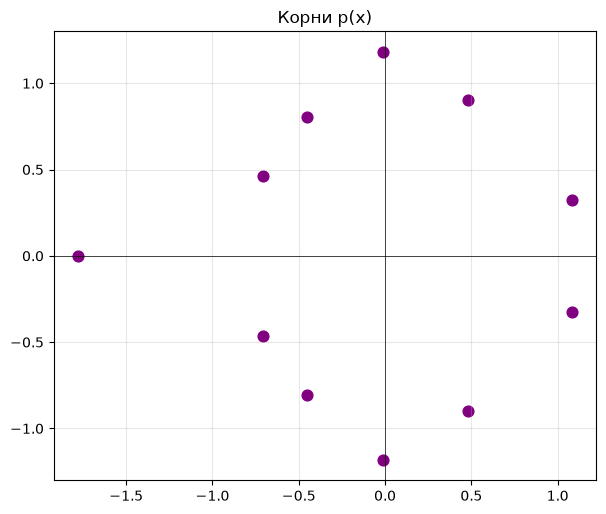

In [11]:
x = symbols('x')
p = x**11 + x**10 + x**8 - 2*x**7 - x**5 + x**4 + 2*x**2 + 2*x + 2
roots = nroots(p, n=15)
roots_c = [complex(r.evalf()) for r in roots]
sum_moduli = sum(abs(r) for r in roots_c)
max_re_root = max(roots_c, key=lambda r: r.real)
print('1) |z1|+...+|z11| =', float(sum_moduli))
print('2) max Re =', max_re_root.real, ', root ≈', max_re_root)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter([r.real for r in roots_c], [r.imag for r in roots_c], s=60, c='purple')
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title('Корни p(x)')
plt.show()


---
## 2.7. $C_w^z = \dfrac{\Gamma(z+1)}{\Gamma(w+1)\Gamma(z-w+1)}$


In [12]:
from scipy.special import gamma as Gamma
w_fix, z_fix = 1-1j, 1+1j
C = Gamma(z_fix+1) / (Gamma(w_fix+1)*Gamma(z_fix-w_fix+1))
print('a) C_{1-i}^{1+i} =', C)
print('b) Arg(C) =', cmath.phase(C), 'rad (', np.degrees(cmath.phase(C)), '°)')


a) C_{1-i}^{1+i} = (4.367449140640135+4.851629765157813j)
b) Arg(C) = 0.8378693695500425 rad ( 48.00637865850453 °)


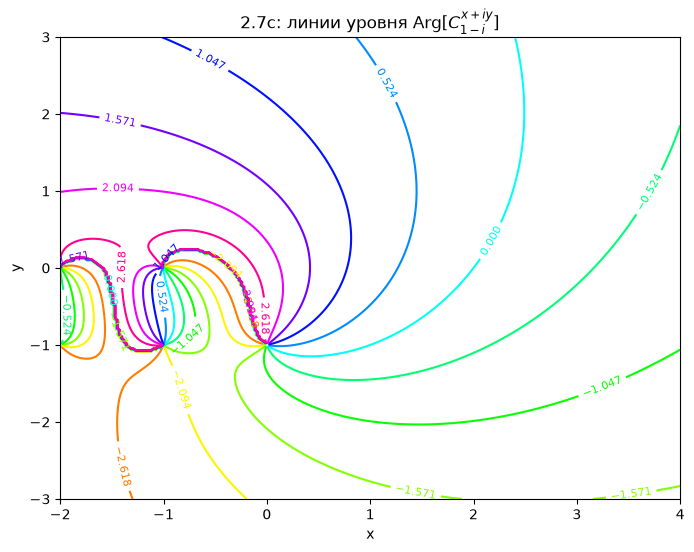

In [13]:
from matplotlib import cm
n = 280
x = np.linspace(-2, 4, n)
y = np.linspace(-3, 3, n)
X, Y = np.meshgrid(x, y)
Z = X + 1j*Y
w0 = 1 - 1j
with np.errstate(all='ignore'):
    Cwz = Gamma(Z+1) / (Gamma(w0+1)*Gamma(Z-w0+1))
    phase = np.angle(Cwz)
fig, ax = plt.subplots(figsize=(8, 6))
cf = ax.contour(X, Y, phase, levels=np.linspace(-np.pi, np.pi, 13), cmap=cm.hsv)
ax.clabel(cf, inline=True, fontsize=8)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(r'2.7c: линии уровня Arg[$C_{1-i}^{x+iy}$]')
plt.show()


---
## 2.8. $\det(A+\lambda I)$

$\lambda^{14}=1$, $\mathrm{Im}\,\lambda>0$, $\mathrm{Re}\,\lambda$ максимален среди таких.


In [14]:
A = np.array([[7, 5], [6, 2]], dtype=complex)
roots14 = [cmath.exp(2j*cmath.pi*k/14) for k in range(14)]
candidates = [lam for lam in roots14 if lam.imag > 0]
lam = max(candidates, key=lambda l: l.real)
print('lambda =', lam)
det_val = np.linalg.det(A + lam*np.eye(2))
print('1) Re det =', det_val.real)
print('2) Im det =', det_val.imag)


lambda = (0.9009688679024191+0.4338837391175581j)
1) Re det = -7.267790387019496
2) Im det = 4.686785134526052


---
## 2.9*. Множества Жюлиа


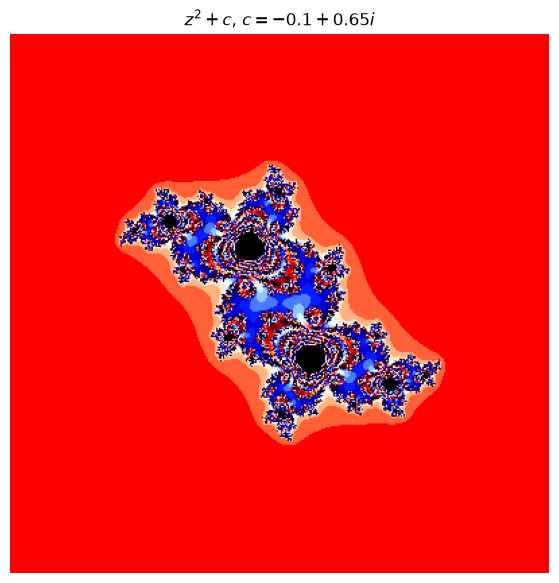

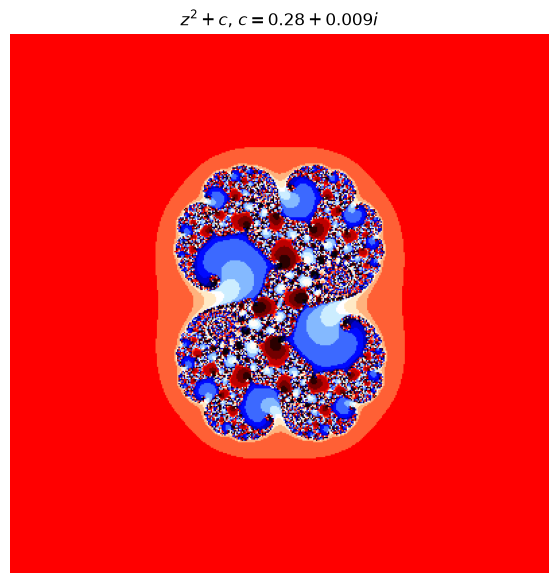

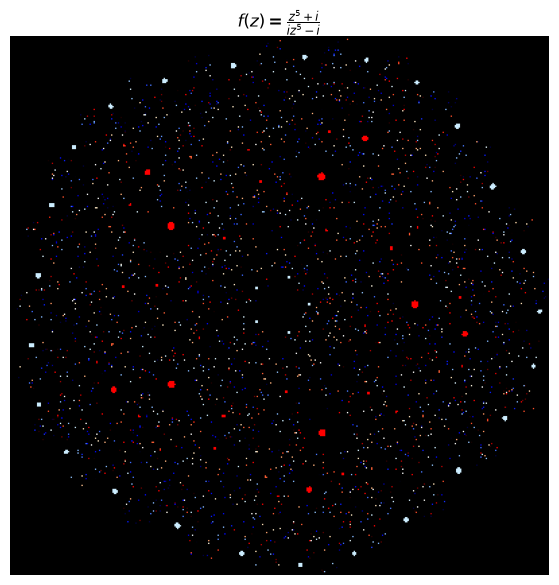

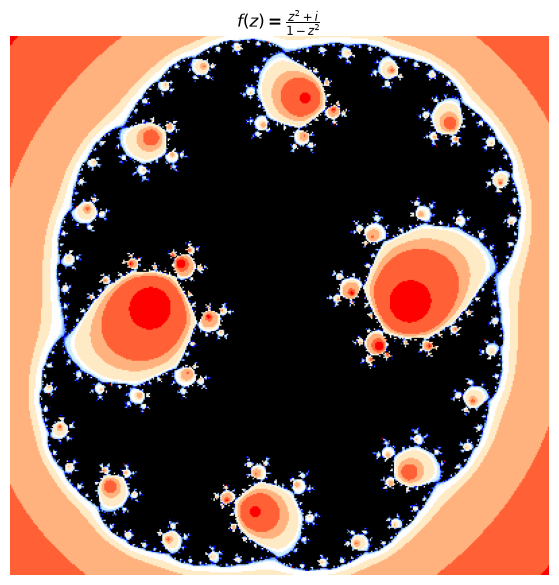

In [15]:
def julia_plot(c, title, ftype='quad', im_width=400, im_height=400,
               xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1, nit_max=800, zabs_max=10):
    xwidth, yheight = xmax - xmin, ymax - ymin
    julia = np.zeros((im_width, im_height))
    for ix in range(im_width):
        for iy in range(im_height):
            z = complex(ix/im_width*xwidth + xmin, iy/im_height*yheight + ymin)
            nit = 0
            while abs(z) <= zabs_max and nit < nit_max:
                if ftype == 'quad':
                    z = z*z + c
                elif ftype == 'rat1':
                    if abs(1j*z**5 - 1j) < 1e-12:
                        break
                    z = (z**5 + 1j) / (1j*z**5 - 1j)
                else:
                    if abs(1 - z*z) < 1e-12:
                        break
                    z = (z*z + 1j) / (1 - z*z)
                nit += 1
            julia[ix, iy] = nit / nit_max
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(julia.T, cmap='flag', extent=[xmin, xmax, ymin, ymax], origin='lower')
    ax.set_title(title)
    ax.axis('off')
    plt.show()

julia_plot(complex(-0.1, 0.65), r'$z^2+c$, $c=-0.1+0.65i$')
julia_plot(complex(0.28, 0.009), r'$z^2+c$, $c=0.28+0.009i$')
julia_plot(0, r'$f(z)=\frac{z^5+i}{iz^5-i}$', ftype='rat1', xmin=-2, xmax=2, ymin=-2, ymax=2)
julia_plot(0, r'$f(z)=\frac{z^2+i}{1-z^2}$', ftype='rat2')
